# PCA and residual reversal on the expanded stock panel

October 29, 2026. The user accepted the existing **200-stock panel**, rather than collecting 300. [Detailed findings](experiments/equity_expanded_pca_reversal/README.md), [specification](experiments/equity_expanded_pca_reversal/specification.json), [source](experiments/equity_expanded_pca_reversal.py), [persistence/regime proposal](PERSISTENCE_REGIME_IDEAS.md).

**Main result:** the broad daily strategy has positive later gross point estimates, unlike the original thirty-stock result, but every reported daily mean interval still includes zero. This is a more favorable unconfirmed baseline, not an established edge. Longer frozen holds also do not establish reversal.

A separate representation illustration tests what changes when points are stock factor loadings or historical factor states. It is **not a profitable-regime model**. Original data and frozen experiments are preserved. All performance is pre-fee and the already examined history remains exploratory.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
cwd=Path.cwd()
candidates=[cwd,cwd/"TDA_Research",cwd/"Senior-Fall"/"TDA_Research",*cwd.parents]
project=next(p for p in candidates if (p/"START_HERE.md").is_file() and (p/"equity").is_dir())
root=project/"equity"
out=root/"experiments"/"equity_expanded_pca_reversal"
result=json.loads((out/"summary.json").read_text())
audit=json.loads((out/"independent_audit.json").read_text())
daily=pd.read_csv(out/"daily_gross_returns.csv")
events=pd.read_csv(out/"horizon_events.csv")
performance=pd.read_csv(out/"gross_performance.csv")
horizon=pd.read_csv(out/"horizon_summary.csv")
paired=pd.read_csv(out/"paired_universe_differences.csv")
description=pd.read_csv(out/"descriptive_summary.csv")
assert all(result["checks"].values()) and all(audit["checks"].values())
print("Date counts:",result["daily_dates_by_period"])
print("Prior fits: 120 primary; 252 sensitivity. Admission: 272 contiguous prior returns.")
print("Primary models: SPY only and SPY + 3 residual PCs. Additional: sectors, average linkage, 10 PCs.")
print("No new data, fees, or regime filter.")

Date counts: {'development': 1738, 'later': 708}
Prior fits: 120 primary; 252 sensitivity. Admission: 272 contiguous prior returns.
Primary models: SPY only and SPY + 3 residual PCs. Additional: sectors, average linkage, 10 PCs.
No new data, fees, or regime filter.


## 1. What PCA now says

The descriptive fit uses 2016–2023 only. For the larger panel, 182 stocks have complete data within that interval, so they enter this balanced descriptive matrix. Daily trading separately admits stocks as their prior histories become available; it does not use this full-period completeness choice.

PC1 captures **41.23%** of standardized variation and its score correlates **0.9738** with SPY. The first ten PCs capture **61.27%**, versus **80.43%** on the original thirty names. The larger selected basket contains more variation outside the same ten-component budget. These are reconstruction statistics, not percentages of future returns predicted.

The heatmap shows average stock/component score correlations within current sectors. Its colors describe the fitted sample, not causal economic drivers. PCA signs are arbitrary.

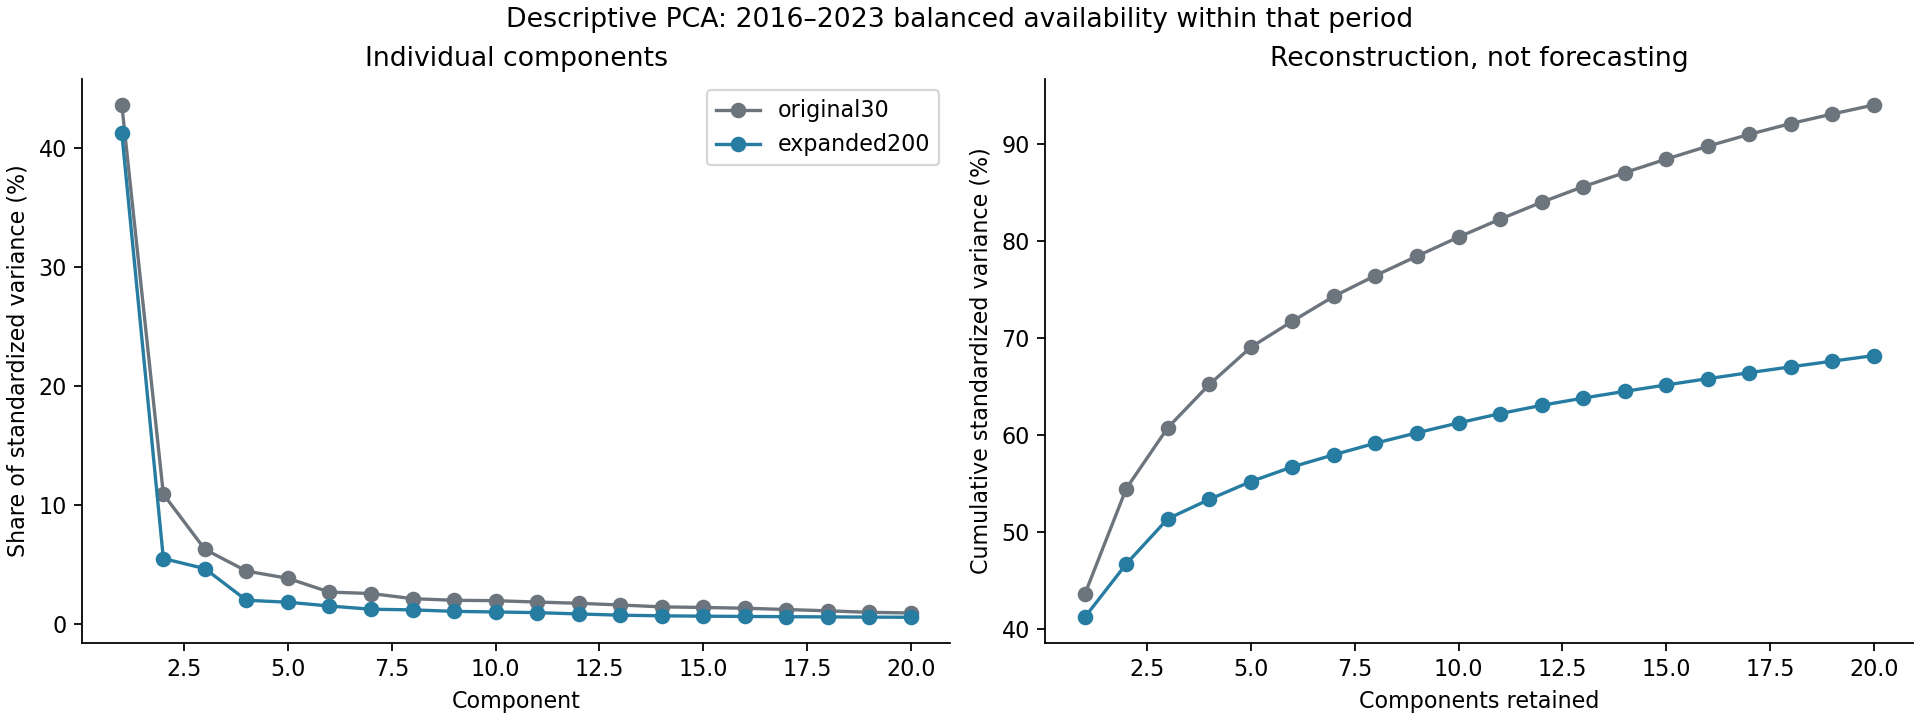

,universe,stocks,return_observations,first_date,last_date,PC1_fraction,PC3_cumulative,PC10_cumulative,PC1_SPY_correlation
0,original30,30,2011,2016-01-05,2023-12-29,0.43591,0.60779,0.80427,0.92755
1,expanded200,182,2011,2016-01-05,2023-12-29,0.41229,0.51387,0.61266,0.97381


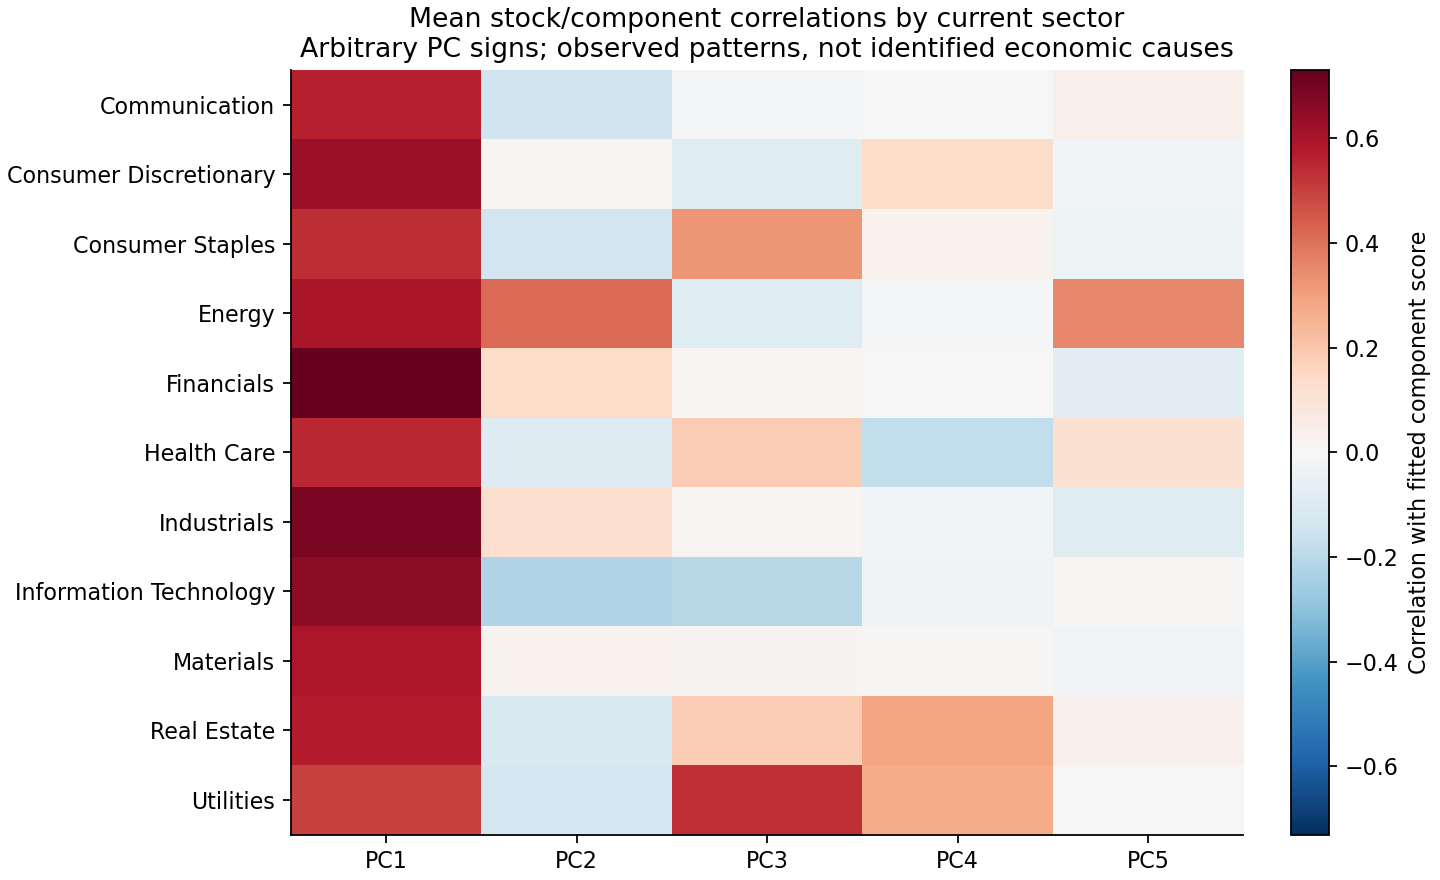

In [2]:
display(Image(filename=str(out/"01_descriptive_pca.png")))
display(description.drop(columns="omitted_short_histories").round(5))
display(Image(filename=str(out/"02_descriptive_sector_loadings.png")))

## 2. The broader daily strategy has a different observed return result

The original strategy observes a one-day adjusted log-return signal after prior fitting, then trades from the **next raw vendor daily-bar open to the same day's close**, at unit gross, flat nightly. Weighting is minus W times the WLS residual. All comparisons keep the timing and signal unchanged.

With the original 120-session fit, the later broader SPY-only mean is **+1.143 bps/day**, interval **[-0.692,+3.395]**; three PCs give **+1.343**, interval **[-0.530,+3.452]**. The same thirty-stock control remains at **-1.291/-0.646**. Every model/lookback/period daily mean interval includes zero.

The plots compound daily returns. Full-run starting equity and later-period-reset starting equity are separate $100,000 illustrations. They are not actual P&L or a guarantee of execution at verified regular-session auctions.

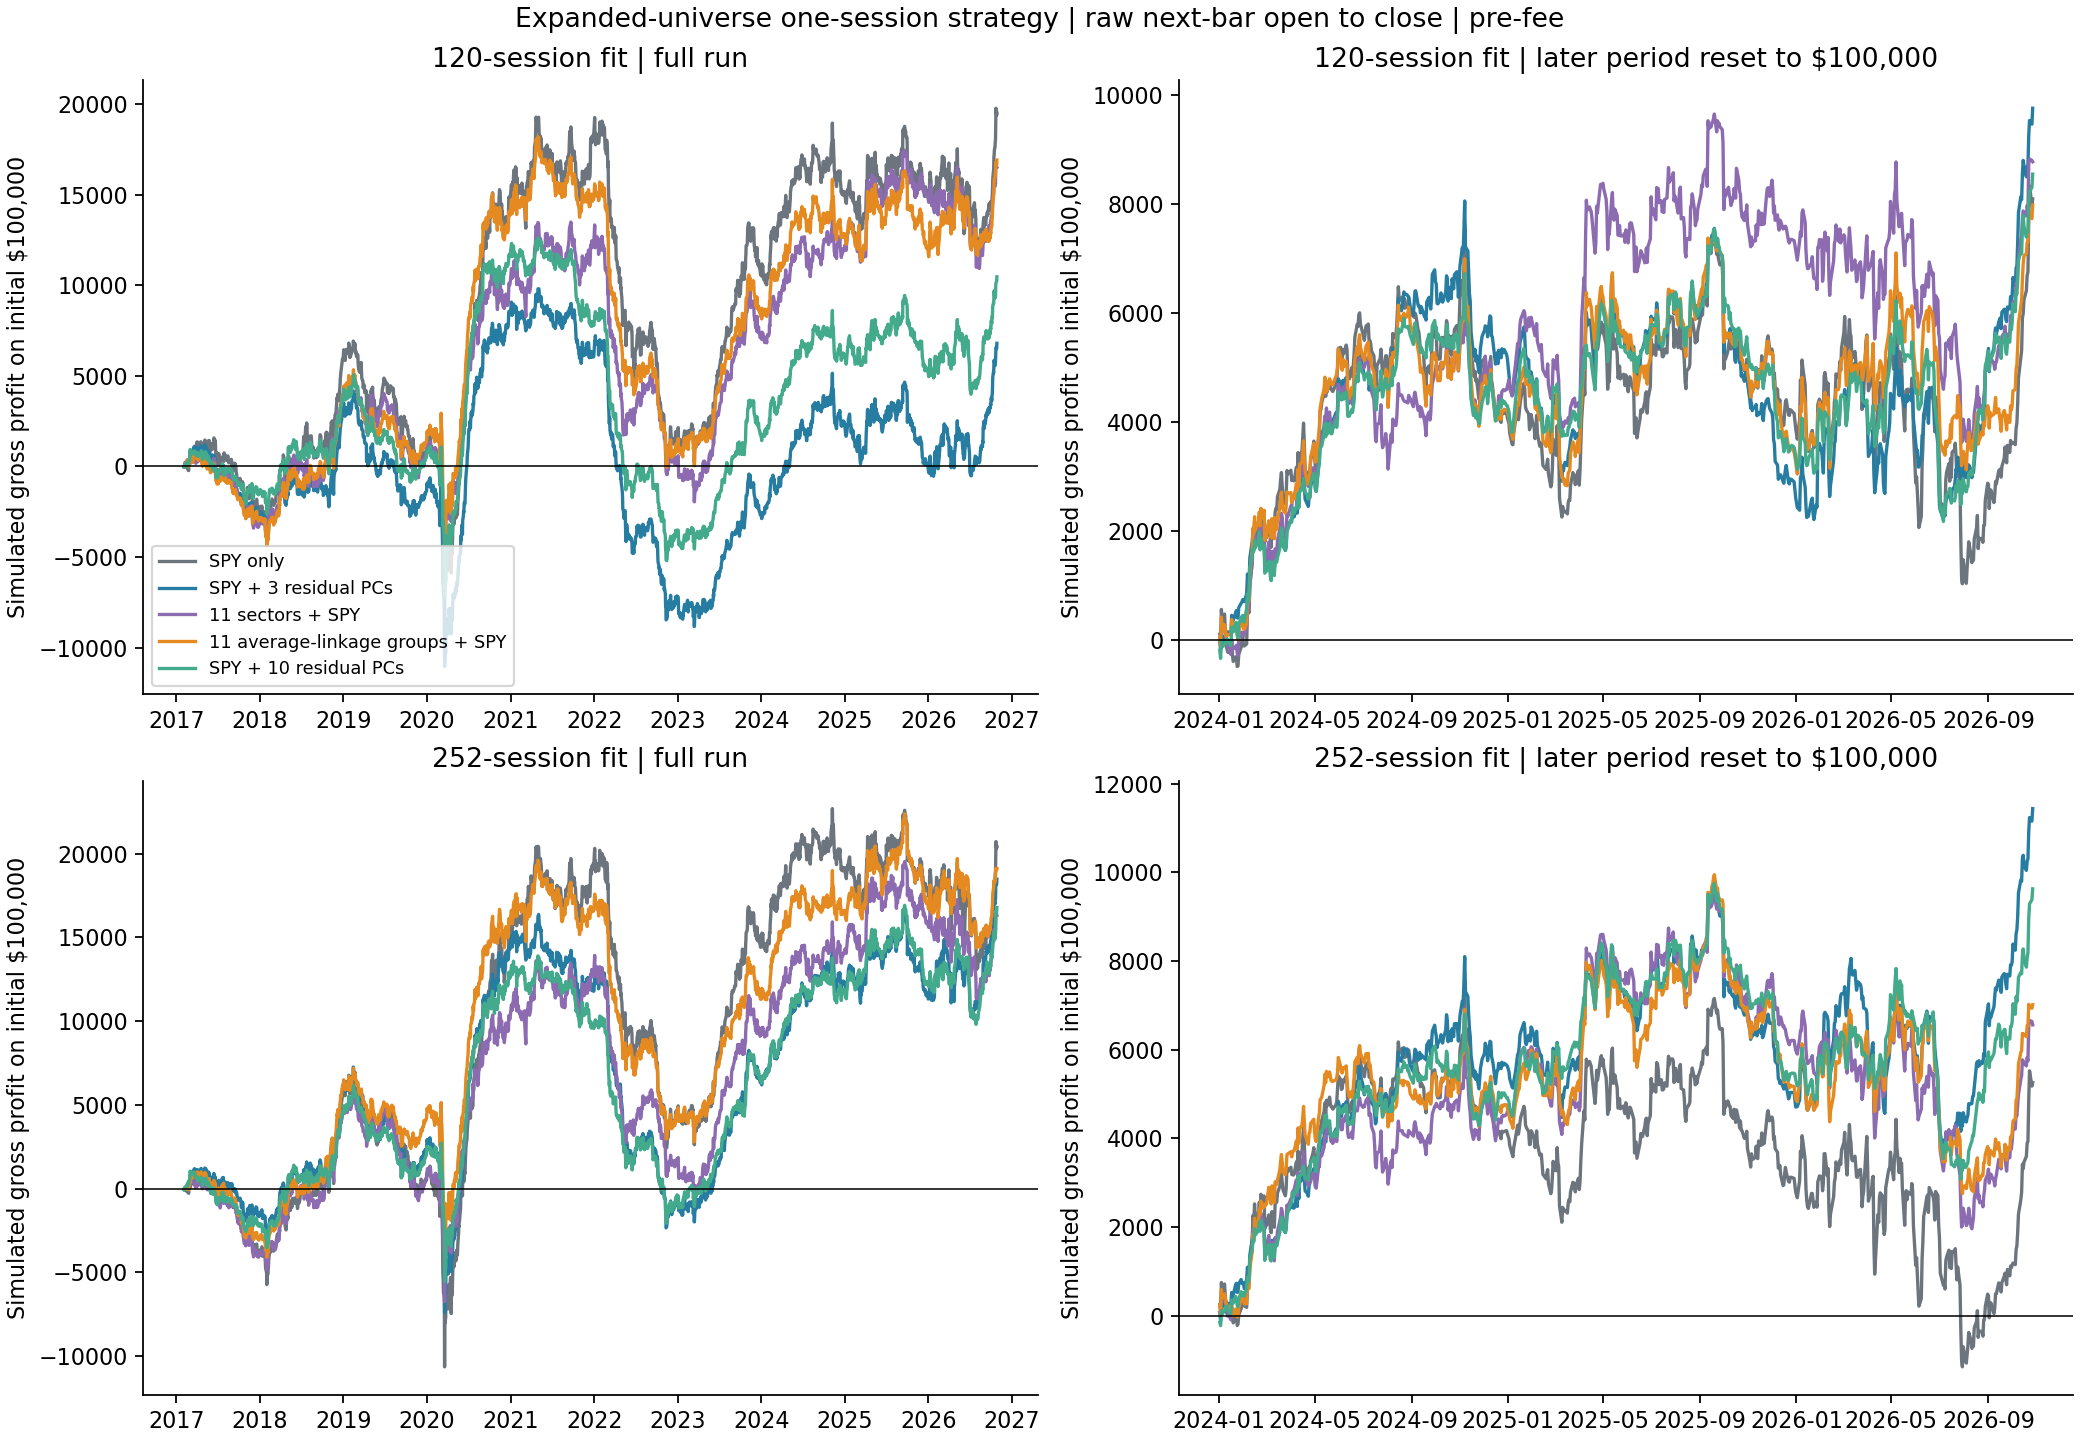

,universe,window,model,days,mean_daily_bps,mean_low,mean_high,sharpe_vs_zero,gross_CAGR,mean_effective_breadth
14,expanded200,120,Average11,708,1.11569,-0.44170,2.97052,0.69960,0.02768,89.49829
15,expanded200,120,SPY_PCA10,708,1.17937,-0.39521,2.96233,0.89714,0.02960,90.19469
16,expanded200,120,SPY_PCA3,708,1.34269,-0.53009,3.45233,0.88996,0.03367,89.95451
17,expanded200,120,SPY_only,708,1.14277,-0.69205,3.39546,0.60890,0.02807,91.77358
18,expanded200,120,Sector11,708,1.22021,-0.30791,2.94331,0.75214,0.03037,92.70593
19,expanded200,252,Average11,708,0.98856,-0.64238,2.93165,0.62538,0.02441,91.60035
20,expanded200,252,SPY_PCA10,708,1.31948,-0.33593,3.11868,1.00654,0.03324,91.77132
21,expanded200,252,SPY_PCA3,708,1.55954,-0.24398,3.53528,1.00585,0.03929,92.26672
22,expanded200,252,SPY_only,708,0.76865,-1.10260,3.02511,0.40419,0.01839,94.12333
23,expanded200,252,Sector11,708,0.93135,-0.67136,2.68690,0.56343,0.02286,94.80897


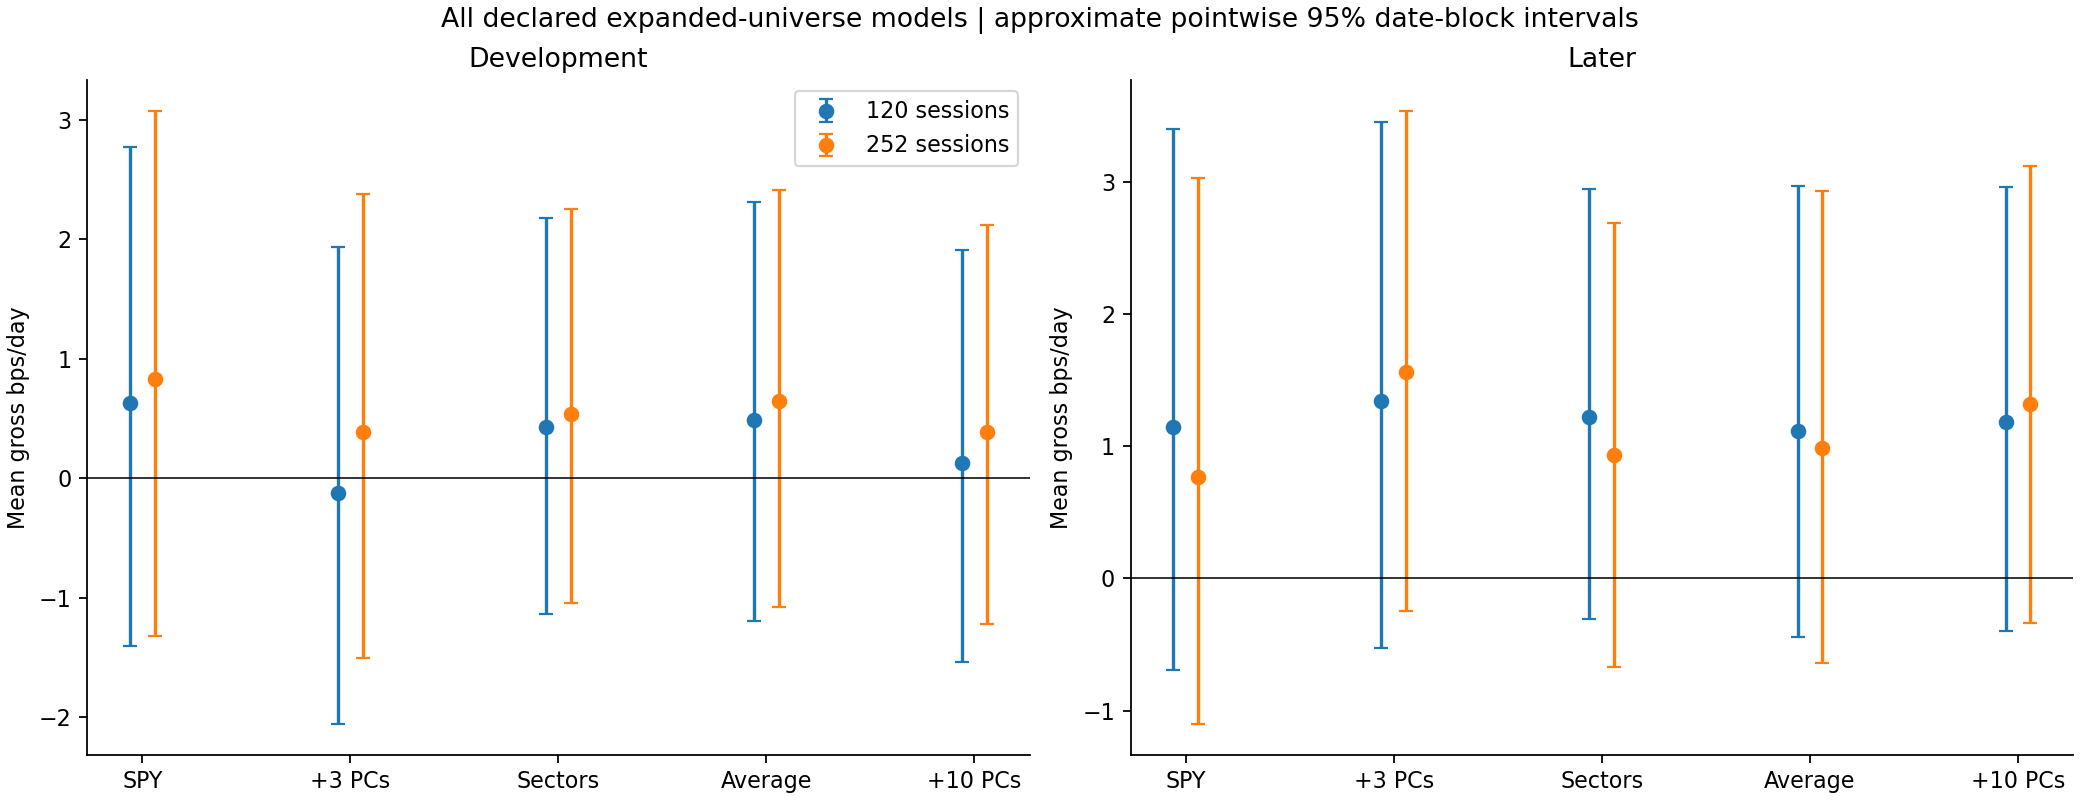

In [3]:
display(Image(filename=str(out/"03_gross_profit.png")))
display(performance.loc[performance.period.eq("later"),["universe","window","model","days","mean_daily_bps","mean_low","mean_high","sharpe_vs_zero","gross_CAGR","mean_effective_breadth"]].round(5))
display(Image(filename=str(out/"04_daily_mean_intervals.png")))
assert ((performance.mean_low<0)&(performance.mean_high>0)).all()

## 3. Comparison with the original basket and date/price conventions

Original thirty-stock controls use identical dates and fit lengths. Their 120-session returns reproduce all **4,892 overlapping saved model/date rows** of the frozen original study. That is a check on implementation, not a fresh holdout result.

Some paired broad-minus-original intervals favor the broader strategy, particularly SPY-only, while standalone broad means remain uncertain. These are pointwise exploratory comparisons and do not show that adding arbitrary stocks must improve returns.

The event analysis needs complete twenty-session outcomes and consistent adjusted prices, unlike the raw-bar daily strategy. Below, we reconcile the apparently different one-session means and save a reproducible convention bridge. The nineteen later tail dates have favorable realized returns; they are not selected as a future trading regime. Annual returns are descriptive, with partial first/last years.

In [4]:
display(paired.round(5))
rows=[]
for (period,universe,window,model),f in daily.groupby(["period","universe","window","model"]):
    g=events.loc[events.period.eq(period)&events.universe.eq(universe)&events.window.eq(window)&events.model.eq(model)&events.horizon.eq(1)]
    common=f.loc[f.signal_date.isin(g.signal_date)];omitted=f.loc[~f.signal_date.isin(g.signal_date)]
    rows.append({"period":period,"universe":universe,"window":window,"model":model,
        "all_daily_dates":len(f),"all_raw_mean_bps":f.gross_return.mean()*1e4,
        "common_event_dates":len(common),"common_raw_mean_bps":common.gross_return.mean()*1e4,
        "common_adjusted_mean_bps":g.gross_event_return.mean()*1e4,
        "omitted_dates":len(omitted),"omitted_raw_mean_bps":omitted.gross_return.mean()*1e4})
bridge=pd.DataFrame(rows)
bridge.to_csv(out/"one_session_convention_bridge.csv",index=False)
display(bridge.loc[bridge.period.eq("later")&bridge.universe.eq("expanded200")&bridge.window.eq(120)&bridge.model.isin(["SPY_only","SPY_PCA3"])].round(5))
annual=[]
for (universe,window,model,year),f in daily.assign(year=pd.to_datetime(daily.date).dt.year).groupby(["universe","window","model","year"]):
    annual.append({"universe":universe,"window":window,"model":model,"year":int(year),"sessions":len(f),
        "gross_return":float(np.prod(1+f.gross_return)-1),"mean_daily_bps":float(f.gross_return.mean()*1e4)})
pd.DataFrame(annual).to_csv(out/"annual_gross_returns.csv",index=False)

,period,window,model,expanded_minus_original_mean_bps,low,high
0,development,120,SPY_only,0.08291,-1.44493,1.59887
1,development,120,SPY_PCA3,0.17290,-1.20995,1.59359
2,development,252,SPY_only,-0.04610,-1.66171,1.40866
3,development,252,SPY_PCA3,-0.31503,-1.59379,0.89413
4,later,120,SPY_only,2.43354,0.37784,4.61765
5,later,120,SPY_PCA3,1.98860,-0.13431,4.28831
6,later,252,SPY_only,2.24920,0.14511,4.69499
7,later,252,SPY_PCA3,1.89012,-0.33361,4.36446


,period,universe,window,model,all_daily_dates,all_raw_mean_bps,common_event_dates,common_raw_mean_bps,common_adjusted_mean_bps,omitted_dates,omitted_raw_mean_bps
16,later,expanded200,120,SPY_PCA3,708,1.34269,689,0.90473,0.90294,19,17.22456
17,later,expanded200,120,SPY_only,708,1.14277,689,0.55556,0.55339,19,22.43691


## 4. Frozen one-, five-, and twenty-session holds

These events hold the initial sleeves, use adjusted prices, and share complete twenty-session target dates. They are not a funded strategy opening overlapping unit-gross positions every day. Initial exposure neutrality may drift. In the later period, the 120-session three-PC twenty-session mean is about **-3.68 bps/event**, with interval **[-13.03,+5.72]**.

Every expanded event-mean and overall response-slope interval includes zero across the declared models, lookbacks, and periods. A longer frozen hold has not established an edge or a preferred horizon. This does not test a price-equilibrium spread or multi-year valuation mean reversion.

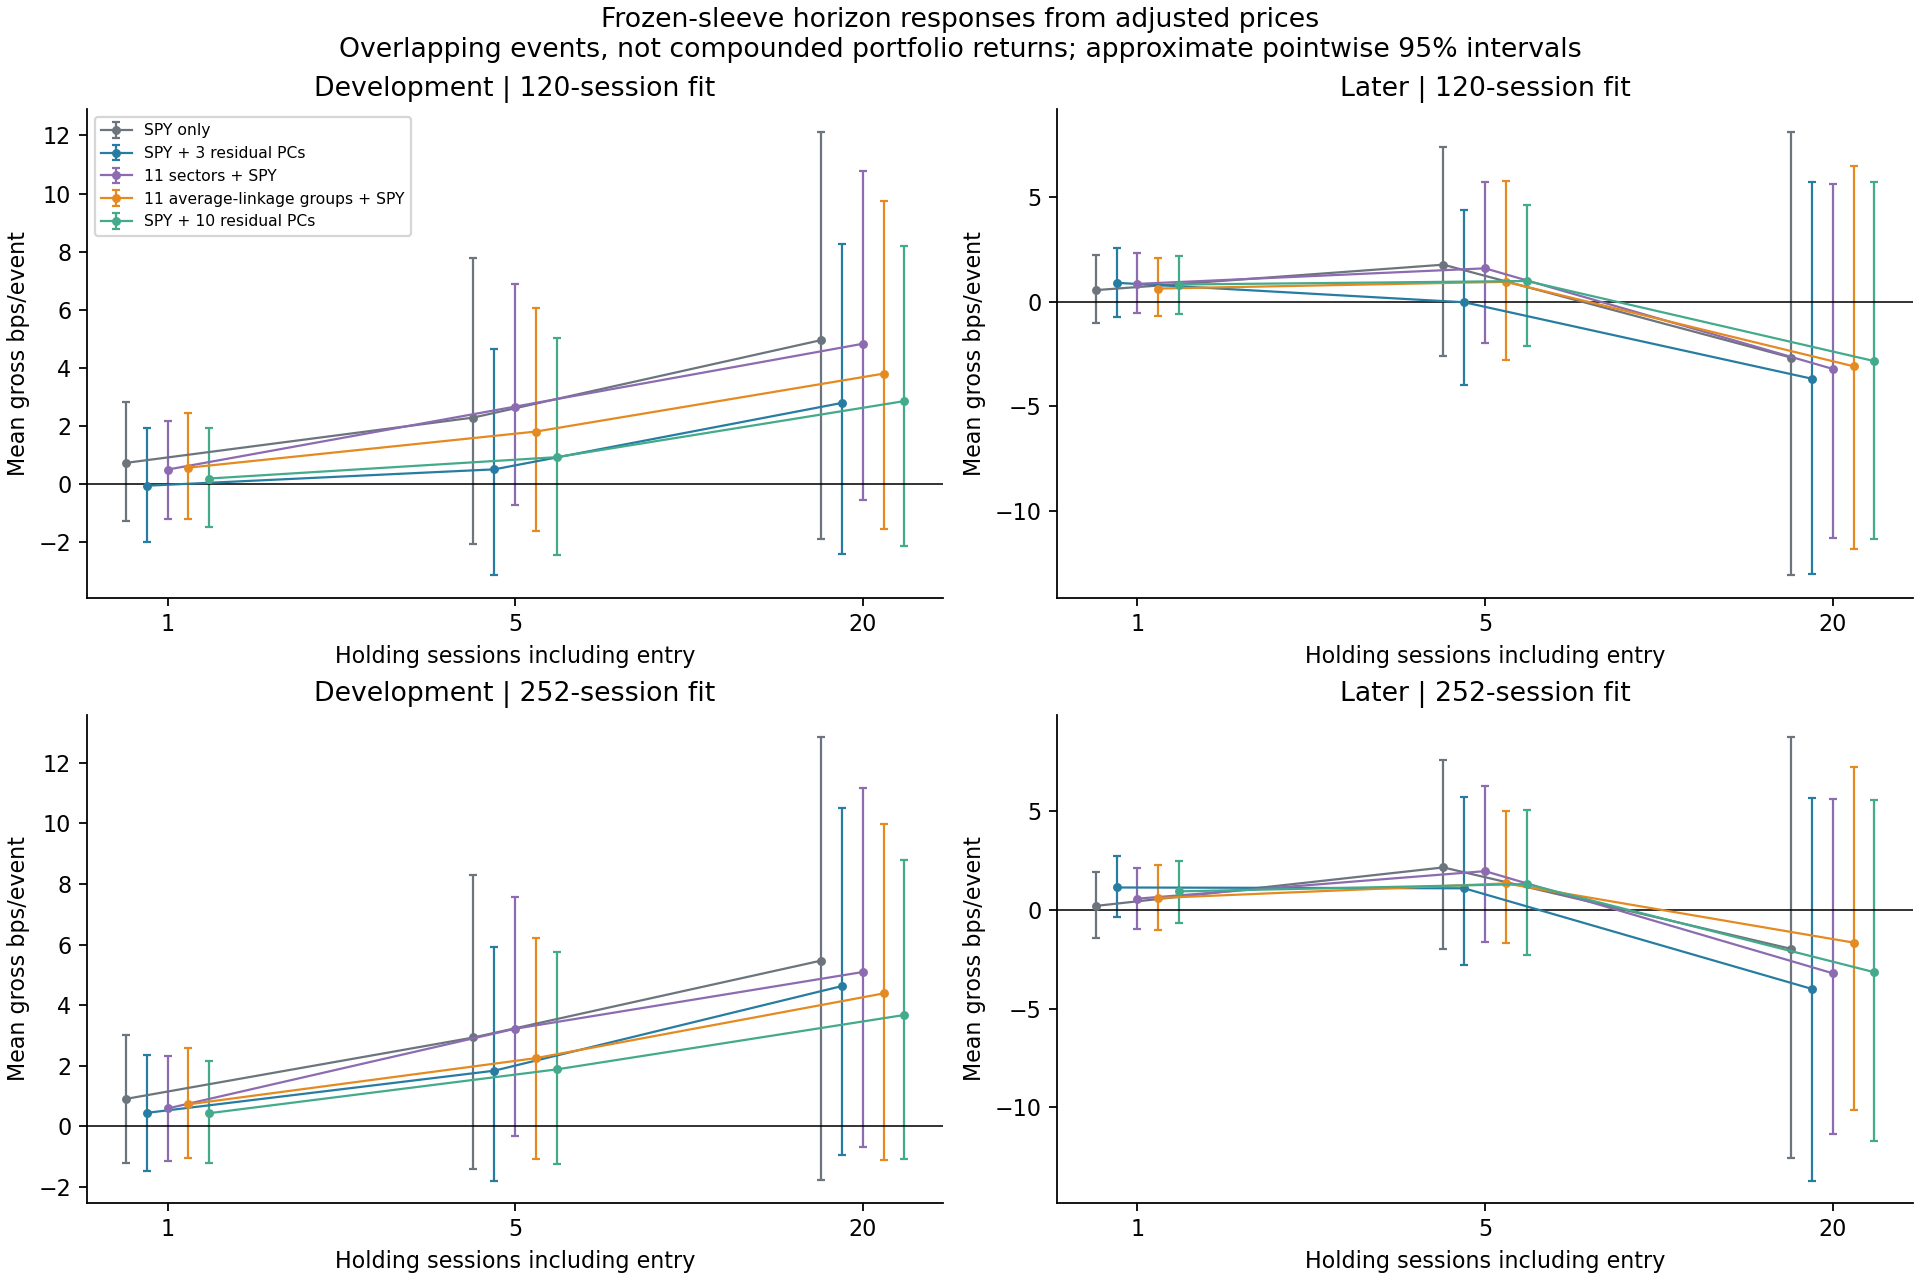

,period,universe,window,model,horizon,events,mean_event_bps,mean_low,mean_high,response_slope,slope_low,slope_high
48,later,expanded200,120,SPY_PCA3,1,689,0.90294,-0.73674,2.55466,-0.00552,-0.01403,0.00264
49,later,expanded200,120,SPY_PCA3,5,689,-0.02767,-3.96735,4.38959,-0.00076,-0.02315,0.01887
50,later,expanded200,120,SPY_PCA3,20,689,-3.68470,-13.03217,5.71643,0.01229,-0.03412,0.05813
51,later,expanded200,120,SPY_only,1,689,0.55339,-1.02255,2.21458,-0.00420,-0.01236,0.00325
52,later,expanded200,120,SPY_only,5,689,1.77015,-2.60397,7.39200,-0.00873,-0.03564,0.01492
53,later,expanded200,120,SPY_only,20,689,-2.67287,-13.09297,8.14046,0.00472,-0.04744,0.05846
63,later,expanded200,252,SPY_PCA3,1,689,1.13243,-0.38616,2.71195,-0.00661,-0.01405,0.00087
64,later,expanded200,252,SPY_PCA3,5,689,1.09176,-2.78456,5.71439,-0.00735,-0.03109,0.01412
65,later,expanded200,252,SPY_PCA3,20,689,-4.00036,-13.70483,5.65974,0.01351,-0.03591,0.06490
66,later,expanded200,252,SPY_only,1,689,0.19891,-1.40610,1.89840,-0.00160,-0.00999,0.00673


In [5]:
display(Image(filename=str(out/"05_horizon_event_returns.png")))
display(horizon.loc[horizon.period.eq("later")&horizon.universe.eq("expanded200")&horizon.model.isin(["SPY_only","SPY_PCA3"])].round(5))
expanded=horizon.loc[horizon.universe.eq("expanded200")]
assert ((expanded.mean_low<0)&(expanded.mean_high>0)).all()
assert ((expanded.slope_low<0)&(expanded.slope_high>0)).all()

## 5. What if factor coefficients become the coordinates?

We must distinguish **one stock's exposures** from **one day's factor scores**. The first groups stocks by sensitivity; the second describes combinations of market moves across days.

For standardized-return PCA, the full eigenvalue-weighted loading matrix **V sqrt(Lambda)** reproduces the correlation geometry. Its distance identity is checked. Keeping only three columns changes the geometry by retaining common patterns and discarding other variation. The rightmost cloud instead has one point per historical day in three score coordinates.

The diagram comparison is one historical illustration, before any future-profit labels. It uses 198 stock points versus 252 day points, each geometry rescaled by its own median distance. More bars, a longer interval, or a different-looking H1 plot is not evidence of a profitable regime or an economic cycle. H0's infinite interval is omitted from the picture but retained in saved arrays.

Full weighted-loading distance identity error: 8.631984016460592e-15


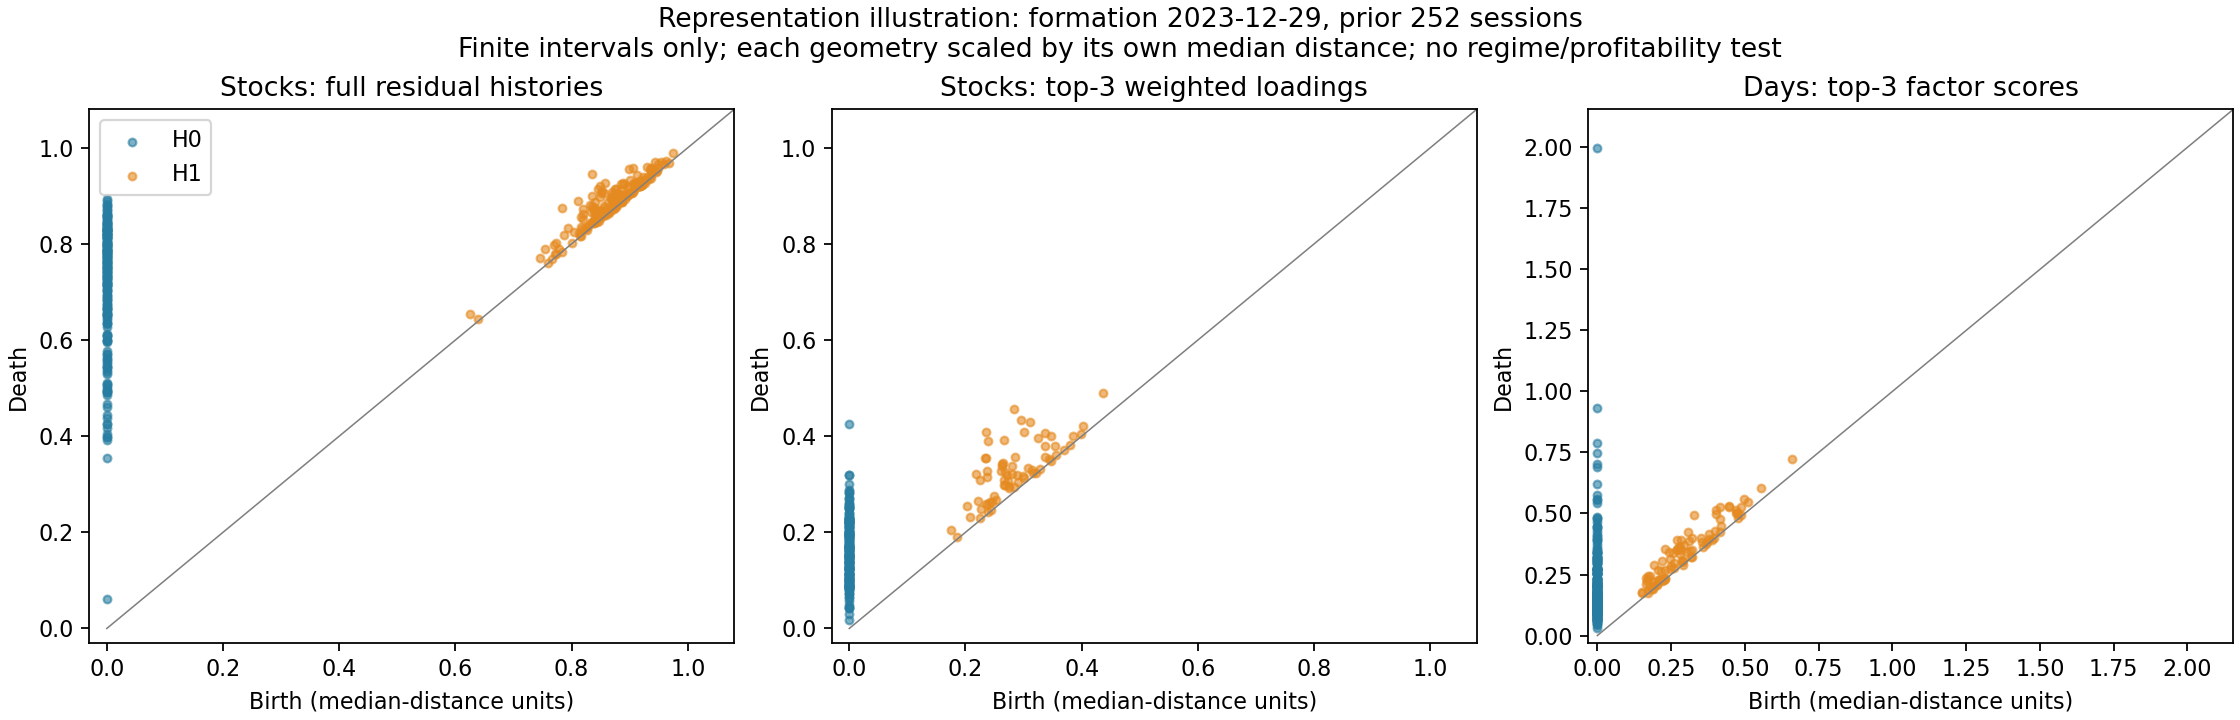

,representation,points,original_median_distance,finite_H0_bars,finite_H1_bars,H1_max_lifetime_normalized
0,Stocks_return_history,198,1.400962,197,184,0.109652
1,Stocks_top3_loadings,198,0.584364,197,68,0.174703
2,Days_top3_scores,252,7.728267,251,90,0.165254


In [6]:
display(Image(filename=str(out/"06_representation_diagrams.png")))
display(pd.read_csv(out/"representation_snapshot_summary.csv").round(6))
print("Full weighted-loading distance identity error:",result["representation_control"]["full_weighted_loading_distance_identity_max_error"])
assert result["representation_control"]["full_weighted_loading_distance_identity_max_error"]<1e-7

## 6. Why time ordering matters for a reversal-regime idea

Here is a **synthetic control**, not financial data. Two sequences contain exactly ten -1 values and ten +1 values. One alternates every observation; the other has a run of negatives followed by a run of positives. Their unordered point clouds and ordinary persistence diagrams are identical, even though lag-one dependence differs.

Using consecutive pairs as coordinates creates transition points. Those clouds can now differ. This demonstrates what the lag construction preserves, not that a diagram improves on ordinary autocorrelation. Such a comparator is essential.

In [7]:
from ripser import ripser
alternating=np.tile([-1.,1.],10)
blocked=np.r_[np.full(10,-1.),np.full(10,1.)]
def finite_H0(points):
    diagram=ripser(points,maxdim=0)["dgms"][0]
    return np.sort(diagram[np.isfinite(diagram[:,1]),1])
plain_a=finite_H0(alternating[:,None]);plain_b=finite_H0(blocked[:,None])
lag_a=finite_H0(np.column_stack([alternating[1:],alternating[:-1]]))
lag_b=finite_H0(np.column_stack([blocked[1:],blocked[:-1]]))
assert np.array_equal(np.sort(alternating),np.sort(blocked))
assert np.allclose(plain_a,plain_b)
lag_same=len(lag_a)==len(lag_b) and np.allclose(lag_a,lag_b)
assert not lag_same
toy={"synthetic_not_financial_data":True,"unordered_observations_equal":True,
    "ordinary_H0_equal":True,"lag_transition_H0_equal":bool(lag_same),
    "alternating_lag1_correlation":float(np.corrcoef(alternating[1:],alternating[:-1])[0,1]),
    "blocked_lag1_correlation":float(np.corrcoef(blocked[1:],blocked[:-1])[0,1])}
(out/"temporal_order_control.json").write_text(json.dumps(toy,indent=2)+"\n")
display(pd.DataFrame([toy]))

,synthetic_not_financial_data,unordered_observations_equal,ordinary_H0_equal,lag_transition_H0_equal,alternating_lag1_correlation,blocked_lag1_correlation
0,True,True,True,False,-1.0,0.9


## 7. Proposed regime question and audit

The next forecast target should be the **fixed daily strategy's next twenty daily trades**, rather than labeling attractive historical years after looking at their profits. A simple past-only state model should be compared with the same model plus a few fixed diagram features. Completed target labels, purged chronological boundaries, past-only scaling, point-count/volatility controls, and a conventional lag-dependence baseline are necessary.

The [regime proposal](PERSISTENCE_REGIME_IDEAS.md) distinguishes stock-loading, daily-state, and lagged-state objects and lists the choices still to fix. It is a concrete research design, not a fitted profitability filter. A persistence landscape is one statistical encoding option; no financial benefit is assumed.

The broader sample has more favorable measured gross returns but still current-survivor selection, current classifications, ideal vendor-bar execution, and examined-history limitations. Positive point estimates do not restore unseen time or identify a mechanism.

In [8]:
for name,passed in audit["checks"].items():
    print(name,passed)
print("Historical rows reproduced:",audit["historical_rows_checked"])
print("Maximum historical return reproduction error:",audit["historical_daily_return_reproduction_error"])
print("Maximum independent position reconstruction error:",audit["max_independent_position_error"])
assert all(audit["checks"].values())

past_only_common_admission_and_chronology True
all_daily_and_horizon_ledgers_reconciled True
initial_gross_and_dollar_constraints True
thirteen_dates_independently_reconstructed_with_covariance_eigenvectors_and_WLS_normal_equations True
future_relative_projection_slope_identity True
original30_all_overlap_dates_reproduce_frozen_strategy True
all_daily_event_slope_and_paired_universe_intervals_reproduced True
descriptive_PCA_independently_reproduced True
prior_data_sources_and_results_unchanged True
Historical rows reproduced: 4892
Maximum historical return reproduction error: 3.0010716134398763e-16
Maximum independent position reconstruction error: 1.3600232051658168e-15
